In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix,ConfusionMatrixDisplay,accuracy_score
from sklearn.neighbors import KNeighborsClassifier

In [2]:
df = pd.read_csv("features_clean.csv")
df.head()

,genre,artist_id,artist,track_id,track,year,tempo,rms_mean,rms_std,centroid_mean,...,chroma8_std,chroma9_mean,chroma9_std,chroma10_mean,chroma10_std,chroma11_mean,chroma11_std,chroma12_mean,chroma12_std,duration_s
0,luk_thung,1441728701,เนย ภัสวรรณ,6764580976,โลกซึมเศร้า,2026.0,66.256010,0.237414,0.059353,2194.821944,...,0.415356,0.245209,0.217966,0.437266,0.412282,0.203564,0.208482,0.248775,0.308715,29.98
1,luk_thung,1441728701,เนย ภัสวรรณ,1871700083,Nakak,2018.0,135.999178,0.136090,0.060338,1727.077584,...,0.160506,0.258428,0.336741,0.210030,0.261645,0.227271,0.228764,0.381742,0.393145,29.98
2,luk_thung,1441728701,เนย ภัสวรรณ,1871701557,Fak Baila,2018.0,129.199219,0.234283,0.076159,1744.828601,...,0.332761,0.322790,0.267680,0.441366,0.388528,0.265553,0.239008,0.329387,0.301659,29.98
3,luk_thung,1441728701,เนย ภัสวรรณ,1871711706,Bpen Peuan Kak Gan Bor Dai,2022.0,151.999081,0.195168,0.068867,2146.807203,...,0.206529,0.303461,0.325730,0.258290,0.258195,0.242755,0.213238,0.359415,0.340324,29.98
4,luk_thung,1441728701,เนย ภัสวรรณ,1871711696,Naang Ngeua Noi (Pra Apai Manee),2020.0,69.837416,0.078079,0.037084,1553.763191,...,0.247497,0.084605,0.144827,0.123084,0.227132,0.120409,0.183482,0.291585,0.339005,29.98


In [3]:
df.shape

(1052, 68)

In [4]:
feature_columns = df.columns.drop(["genre", "artist_id", "artist", "track_id","track", "year", "duration_s"])

In [5]:
x = df[feature_columns]
y = df["genre"]
print(f"X shape: {x.shape}")
print(f"y shape: {y.shape}")

X shape: (1052, 61)
y shape: (1052,)


In [6]:
artists = df[["genre", "artist_id", "artist"]].drop_duplicates(subset="artist_id")
artists.head()

,genre,artist_id,artist
0,luk_thung,1441728701,เนย ภัสวรรณ
12,luk_thung,1233202639,OILLER
24,luk_thung,1388235854,เต๊ะ ตระกูลตอ
36,luk_thung,1230000536,NEK NARUEPOL
48,luk_thung,1130791210,KARN TASANA


In [7]:
artists["genre"].value_counts()

genre
luk_thung    22
pop          22
rock         22
hiphop       22
Name: count, dtype: int64

### Artist-based Test Split
1. **`test_artists`**: Randomly select artists for the test set.
2. **`test_mask`**: Identify all songs belonging to the selected test artists.

In [8]:
test_artists = artists.groupby("genre").sample(n=4,random_state=42)
test_artists

,genre,artist_id,artist
789,hiphop,1316944279,G-BEAR
944,hiphop,1133460295,SARAN
884,hiphop,1464572030,1MILL
800,hiphop,1410138147,OG-ANIC
252,luk_thung,1320057443,กระต่าย พรรณนิภา
156,luk_thung,1396075977,Bell Nipada
96,luk_thung,558340243,Takkatan Chonlada
60,luk_thung,1363877952,Beer Prompong
382,pop,1525357183,Jeff Satur
453,pop,1193225731,BOWKYLION


In [9]:
test_mask = df["artist_id"].isin(test_artists["artist_id"])
test_mask.head()

0    False
1    False
2    False
3    False
4    False
Name: artist_id, dtype: bool

In [10]:
x_train = x.loc[~test_mask]
x_test = x.loc[test_mask]
y_train = y.loc[~test_mask]
y_test = y.loc[test_mask]

In [11]:
print(x_train.shape)
print(x_test.shape)

(862, 61)
(190, 61)


In [12]:
remaining_artists = df.loc[~test_mask, ["genre", "artist_id", "artist"]]
remaining_artists = remaining_artists.drop_duplicates(subset="artist_id")
remaining_artists["genre"].value_counts()

genre
luk_thung    18
pop          18
rock         18
hiphop       18
Name: count, dtype: int64

In [13]:
val_artists = remaining_artists.groupby("genre").sample(n=2,random_state=42)
val_artists["genre"].value_counts()

genre
hiphop       2
luk_thung    2
pop          2
rock         2
Name: count, dtype: int64

In [14]:
val_mask = df["artist_id"].isin(val_artists["artist_id"])
val_mask.head()

0    False
1    False
2    False
3    False
4    False
Name: artist_id, dtype: bool

In [15]:
x_val = x.loc[val_mask]
y_val = y.loc[val_mask]
x_train = x_train.loc[~val_mask]
y_train = y_train.loc[~val_mask]

In [16]:
print(x_train.shape)
print(x_val.shape)
print(x_test.shape)

(766, 61)
(96, 61)
(190, 61)


In [17]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)

In [18]:
genre_codes = {"luk_thung": 0,"pop": 1,"rock": 2,"hiphop": 3}
y_train_number = y_train.map(genre_codes)
y_val_number = y_val.map(genre_codes)
y_test_number = y_test.map(genre_codes)

---

In [19]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train_scaled, y_train_number)
pred1 = knn.predict(x_val_scaled)

In [20]:
print(confusion_matrix(y_val_number, pred1))

[[22  1  1  0]
 [12  6  4  2]
 [ 2  4 13  5]
 [ 0  1  2 21]]


In [21]:
labels = ["luk_thung", "pop", "rock", "hiphop"]
print(classification_report(y_val_number,pred1,labels=[0, 1, 2, 3],target_names=labels,zero_division=0))

              precision    recall  f1-score   support

   luk_thung       0.61      0.92      0.73        24
         pop       0.50      0.25      0.33        24
        rock       0.65      0.54      0.59        24
      hiphop       0.75      0.88      0.81        24

    accuracy                           0.65        96
   macro avg       0.63      0.65      0.62        96
weighted avg       0.63      0.65      0.62        96



In [22]:
error_rate = []
for i in range(1, 30):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train_scaled, y_train_number)
    pred_i = knn.predict(x_val_scaled)
    error_rate.append(np.mean(pred_i != y_val_number))

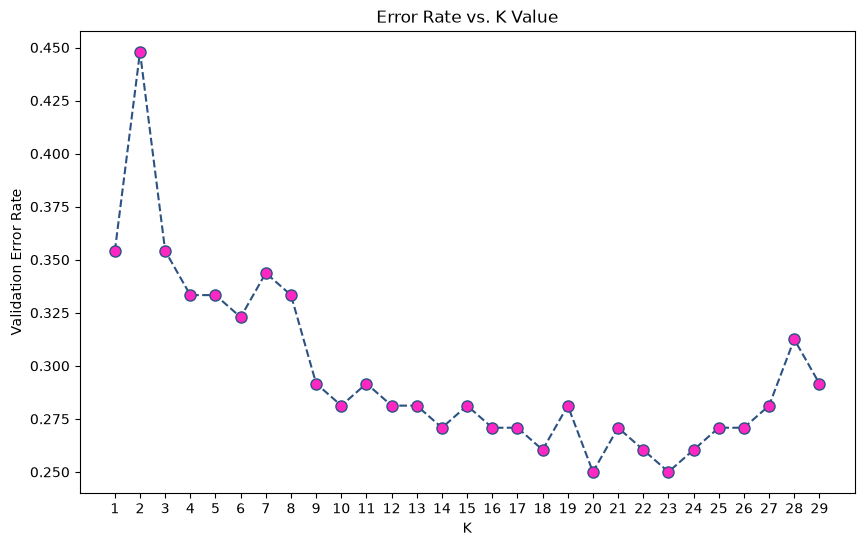

In [23]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 30),error_rate,color="#2C5282",linestyle="dashed",marker="o",markerfacecolor="#FF27C2", markersize=8)
plt.title("Error Rate vs. K Value")
plt.xlabel("K")
plt.ylabel("Validation Error Rate")
plt.xticks(range(1, 30))
plt.grid(False)
plt.show()

ขข

In [24]:
knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(x_train_scaled, y_train_number)
pred_knn_test = knn.predict(x_test_scaled)

In [25]:
test_accuracy = accuracy_score(y_test_number, pred_knn_test)
test_error = 1 - test_accuracy
print(f"Test Accuracy: {test_accuracy * 100:.4f} %")
print(f"Test Error:    {test_error * 100:.4f} %")

Test Accuracy: 63.1579 %
Test Error:    36.8421 %


In [26]:
print(classification_report(y_test_number,pred_knn_test,labels=[0, 1, 2, 3],target_names=labels,zero_division=0))

              precision    recall  f1-score   support

   luk_thung       0.57      0.88      0.69        48
         pop       0.44      0.45      0.44        47
        rock       0.74      0.48      0.58        48
      hiphop       0.92      0.72      0.81        47

    accuracy                           0.63       190
   macro avg       0.67      0.63      0.63       190
weighted avg       0.67      0.63      0.63       190



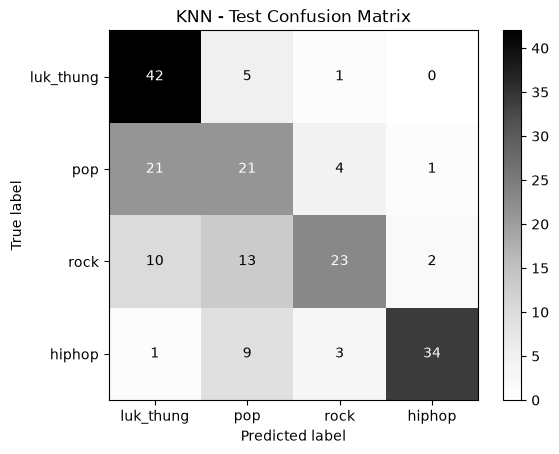

In [27]:
ConfusionMatrixDisplay.from_predictions(y_test_number, pred_knn_test, display_labels=labels, cmap="Greys")
plt.title("KNN - Test Confusion Matrix")
plt.show()